# The guard band filter, demonstrated

`rational`'s demonstration of the guard band filter (`docs/IIR_PLAN.md` I11, IIR-d), made to show it to
others. Every half-band in the engine crosses over at a quarter of its higher rate, the low rate's Nyquist,
so a decimator by 2 folds its transition band onto the **guard band**, the band between the passband edge
and the low Nyquist, and an interpolator images the low rate's guard band into its transition band. The
passband stays alias-free to the profile either way; the guard band does not. The guard band filter
removes it: a 1:1 stage at the low rate, the odd-order Chebyshev II or the linear-phase type II FIR.

**The signal** is a logarithmic sine sweep from 20 Hz to just below the input Nyquist at −6 dBFS, in float,
through the C ABI (`capi/tap_sr_rational_capi.h`), so it runs the **shipping C++** at `economy`: 96 kHz in,
48 kHz out, the passband to 18 kHz, the guard band filter's stop edge at 21.7 kHz, the low Nyquist at
24 kHz. IIR-0's version of this notebook (`iir_spike.ipynb`, section 5) ran scipy designs and said so; this
one runs the library. **One configuration is a reference, not the library:** the filter placed *before*
the decimator, at the high rate, is no named setting of the C ABI, which takes named settings only, so it
is a scipy design run by `sosfilt` and labelled so wherever it appears.

In [1]:
import pathlib, sys, tempfile
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

HERE = pathlib.Path.cwd()
sys.path.insert(0, str(HERE))
import figure_digest  # prints a data digest per figure (A/B gates)
figure_digest.install()
import tap_sr_rational_py as rp
import iir_measure as im

plt.rcParams["figure.dpi"] = 80
PROF = "economy"
A, P = im.PROFILES[PROF]
PASS_HZ, NYQ_HZ = P * im.RATE_LOW, im.RATE_LOW / 2
STOP_HZ = im.stop_edge(PROF, "nonlinear") * im.RATE_LOW  # the same at economy behind every half-band
print("rational", rp.version(), f"| economy: passband to {PASS_HZ:.0f} Hz, the filter's stop edge {STOP_HZ:.0f} Hz,",
      f"the low Nyquist {NYQ_HZ:.0f} Hz")

rational (0, 9, 0) | economy: passband to 18000 Hz, the filter's stop edge 21745 Hz, the low Nyquist 24000 Hz


## The configurations

The FIR half-band, the recursive one in its nonlinear and its near-linear variant, each alone and with each
form of the guard band filter after it (at the named setting behind that half-band: order 7 at `economy`
behind every kind), and the two references: the same order *before* the decimator, and the order before it
that removes the same band.

In [2]:
x, inst = im.sweep(im.RATE_HIGH)
configs = {name: im.run(parts, x) for name, parts in im.configurations("down", PROF).items()}
cost = {name: im.macs_per_output(parts) for name, parts in im.configurations("down", PROF).items()}

order = im.GUARD_ORDER[(PROF, "nonlinear")]
n_match = im.matching_order_before(PROF)
iir = im.half_band("IIR nonlinear", "down", PROF)
for n in (order, n_match):
    sos, edge = im.reference_before(n, PROF)
    pre = signal.sosfilt(sos, x.astype(np.float64)).astype(np.float32)
    name = f"REFERENCE: order {n} before + IIR nonlinear"
    configs[name] = im.run([iir], pre)
    # The high-rate filter runs twice per output frame, five multiplies per section.
    cost[name] = 2 * 5 * len(sos) + float(iir.macs_per_output)
    print(f"{name}: its stop edge {edge * im.RATE_HIGH:.0f} Hz at the high rate, {len(sos)} sections")
print(f"after the decimator, order {order}: {cost['IIR nonlinear + Chebyshev II'] - cost['IIR nonlinear alone']:.0f} "
      f"multiplies per output; before it, order {n_match} to remove the same band: "
      f"{2 * 5 * len(im.reference_before(n_match, PROF)[0]):.0f}")

REFERENCE: order 7 before + IIR nonlinear: its stop edge 32939 Hz at the high rate, 4 sections
REFERENCE: order 17 before + IIR nonlinear: its stop edge 21266 Hz at the high rate, 9 sections
after the decimator, order 7: 20 multiplies per output; before it, order 17 to remove the same band: 90


## Spectrograms

Every configuration on one fixed scale, 0 to −140 dB (0 dB is a full-scale sine; the sweep is at −6 dBFS),
at the output rate, with the passband edge (white), the guard band filter's stop edge (cyan, dashed) and the
low Nyquist (yellow, dotted) drawn. The sweep rises from the bottom left; past 24 kHz in, it folds back down
from the top as an alias. Seventy dB of stopband reads at a glance: the alias leaves the passband dark in
every configuration, and the guard band and the band above it only where a filter stands.

[ figure ] digest 972e56a39e728eef (58 arrays)


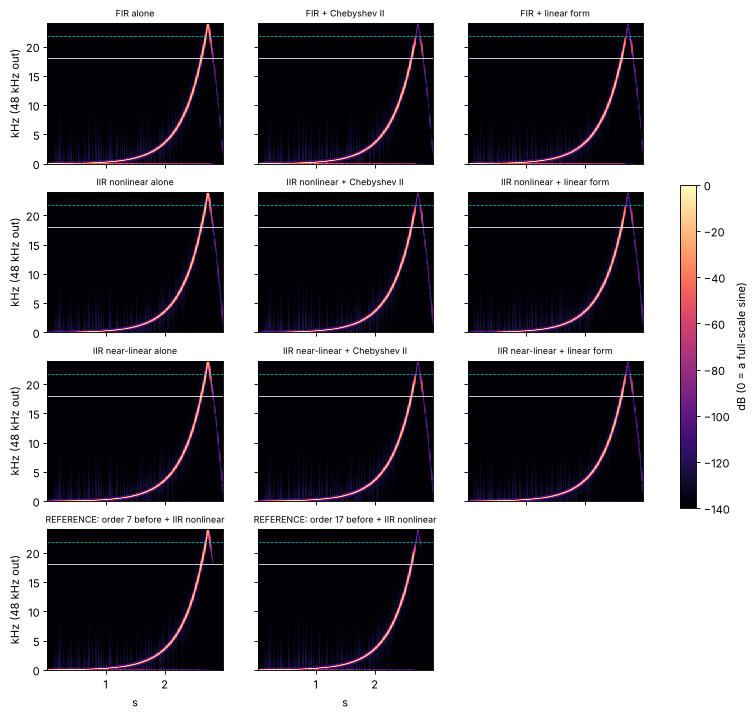

In [3]:
def draw(ax, y, name, rate=im.RATE_LOW, top=None):
    f, tt, s = im.spectrogram(y, rate)
    ax.pcolormesh(tt, f / 1000, s, vmin=-140, vmax=0, shading="auto", cmap="magma", rasterized=True)
    ax.axhline(PASS_HZ / 1000, color="w", lw=0.7)
    ax.axhline(STOP_HZ / 1000, color="c", lw=0.7, ls="--")
    ax.axhline(NYQ_HZ / 1000, color="y", lw=0.9, ls=":")
    ax.set_ylim(0, (top or rate / 2) / 1000)
    ax.set_title(name, fontsize=8)

fig, axes = plt.subplots(4, 3, figsize=(12, 10.5), sharex=True, sharey=True)
for ax, (name, y) in zip(axes.ravel(), configs.items()):
    draw(ax, y, name)
for ax in axes.ravel()[len(configs):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("kHz (48 kHz out)")
for ax in axes[-1, :2]:
    ax.set_xlabel("s")
fig.colorbar(axes[0, 0].collections[0], ax=axes, shrink=0.5, label="dB (0 = a full-scale sine)")
plt.show()

## A waterfall

The same runs as stacked spectra, one every quarter of a second of the sweep, for the nonlinear half-band
alone and with the Chebyshev II after it.

[ figure ] digest 9e74628b4dad5547 (26 arrays)


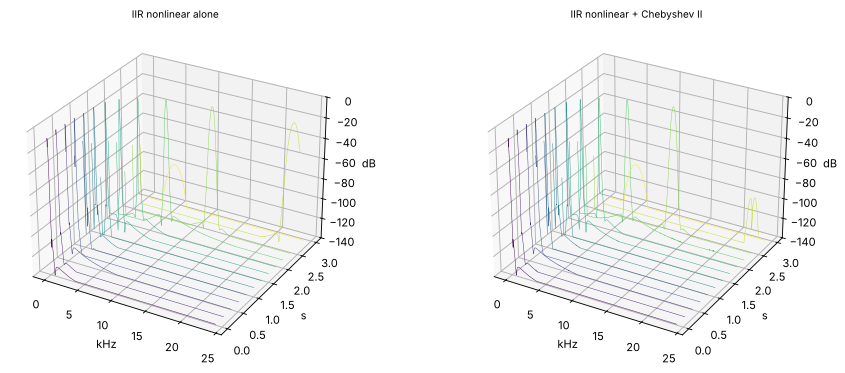

In [4]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
fig = plt.figure(figsize=(12, 4.8))
for i, name in enumerate(("IIR nonlinear alone", "IIR nonlinear + Chebyshev II")):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    f, tt, s = im.spectrogram(configs[name])
    step = max(1, len(tt) // 12)
    for j in range(0, len(tt), step):
        ax.plot(f / 1000, np.full_like(f, tt[j]), np.maximum(s[:, j], -140), lw=0.4, color=plt.cm.viridis(j / len(tt)))
    ax.set_zlim(-140, 0)
    ax.set_xlabel("kHz")
    ax.set_ylabel("s")
    ax.set_zlabel("dB")
    ax.set_title(name, fontsize=9)
    ax.view_init(elev=28, azim=-60)
plt.tight_layout()
plt.show()

## The worst alias

Measured on the sweep: in every 21 ms frame where the input is above the low Nyquist, the power summed over
the band the alias crosses in that frame against the input's power over the band it crosses (both
Blackman–Harris frames, so the scalings cancel), by where the alias lands: in the passband, in the guard
band, or above the filter's stop edge. With the multiplies per output frame of each configuration.

In [5]:
lines = [f"{'configuration':45s} {'passband':>9s} {'guard band':>11s} {'above stop':>11s} {'MACs':>6s}  (dB re the input)"]
for name, y in configs.items():
    t = im.alias_table(y, x, inst, PROF, "nonlinear")
    lines.append(f"{name:45s} {t['passband']:9.1f} {t['guard band']:11.1f} {t['above the stop edge']:11.1f} "
                 f"{cost[name]:6.0f}")
print("\n".join(lines))

configuration                                  passband  guard band  above stop   MACs  (dB re the input)
FIR alone                                         -74.1       -18.3        -8.7     21
FIR + Chebyshev II                                -74.1       -37.3       -79.0     41
FIR + linear form                                 -74.2       -39.8       -80.4     71
IIR nonlinear alone                               -74.8       -22.7        -7.4      4
IIR nonlinear + Chebyshev II                      -74.5       -43.8       -79.6     24
IIR nonlinear + linear form                       -73.5       -46.3       -84.1     54
IIR near-linear alone                             -72.7       -19.4        -6.5      7
IIR near-linear + Chebyshev II                    -72.3       -39.5       -78.9     27
IIR near-linear + linear form                     -71.2       -42.0       -81.3     57
REFERENCE: order 7 before + IIR nonlinear        -107.6       -36.0       -13.1     44
REFERENCE: order 17 befo

## The interpolating mirror

A low-rate sweep, 48 kHz in, through the interpolators by 2 to 96 kHz, with and without the guard band
filter before them. Without it, the input's content between the passband edge and the low Nyquist images
into the half-band's transition band, mirrored about 24 kHz; with it, the images of everything above the
filter's stop edge, which land between 24 kHz and that edge's mirror (26.3 kHz, cyan dash-dot), are gone.

[ figure ] digest 6d9ef5f6e55ff24e (24 arrays)


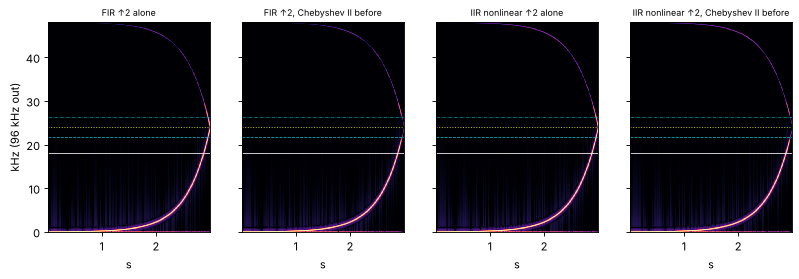

configuration (the filter before)              passband  guard band  above stop  (the worst image, dB re the input, by where its source sits)
FIR alone                                         -73.6       -16.7        -9.2
FIR + Chebyshev II                                -73.6       -37.2       -82.8
IIR nonlinear alone                               -76.5       -20.4        -8.3
IIR nonlinear + Chebyshev II                      -76.8       -43.7       -83.8


In [6]:
x_lo, inst_lo = im.sweep(im.RATE_LOW)
up = {name: parts for name, parts in im.configurations("up", PROF).items()
      if name in ("FIR alone", "FIR + Chebyshev II", "IIR nonlinear alone", "IIR nonlinear + Chebyshev II")}
outs = {name: im.run(parts, x_lo) for name, parts in up.items()}
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
for ax, (name, y) in zip(axes, outs.items()):
    v, _, form = name.replace(" alone", "").partition(" + ")
    draw(ax, y, f"{v} ↑2" + (f", {form} before" if form else " alone"), rate=im.RATE_HIGH)
    ax.axhline((im.RATE_LOW - STOP_HZ) / 1000, color="c", lw=0.5, ls="-.")
    ax.set_xlabel("s")
axes[0].set_ylabel("kHz (96 kHz out)")
plt.show()
print(f"{'configuration (the filter before)':45s} {'passband':>9s} {'guard band':>11s} {'above stop':>11s}  "
      "(the worst image, dB re the input, by where its source sits)")
for name, y in outs.items():
    t = im.image_table(y, x_lo, inst_lo, PROF, "nonlinear")
    print(f"{name:45s} {t['passband']:9.1f} {t['guard band']:11.1f} {t['above the stop edge']:11.1f}")

## Group delay

Each configuration's group delay over the passband, in output frames at 48 kHz, from the C ABI's getters
(each part's at the output rate, summed, as `tap::dsp::chain` composes them), and the references' from
scipy's design. The FIR half-band and the linear form are flat, an exact latency; the near-linear variant
stays within a hundredth of a frame of its exact delay path; the Chebyshev II adds most at the passband
edge, where its poles are.

[ figure ] digest 71abf5e6509a79c7 (11 arrays)


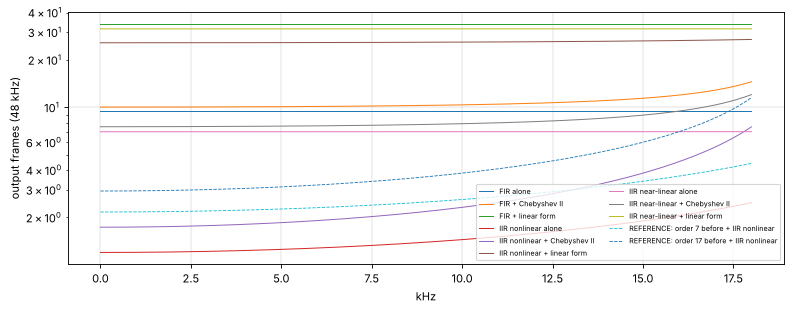

FIR alone                        nominal   9.5000 frames, exact 19/2
FIR + Chebyshev II               nominal  10.0353 frames, no exact latency
FIR + linear form                nominal  34.0000 frames, exact 34
IIR nonlinear alone              nominal   1.1996 frames, no exact latency
IIR nonlinear + Chebyshev II     nominal   1.7349 frames, no exact latency
IIR nonlinear + linear form      nominal  25.6996 frames, no exact latency
IIR near-linear alone            nominal   7.0000 frames, no exact latency
IIR near-linear + Chebyshev II   nominal   7.5353 frames, no exact latency
IIR near-linear + linear form    nominal  31.5000 frames, no exact latency


In [7]:
f = np.linspace(0.0, P, 400)
fig, ax = plt.subplots(figsize=(10, 4))
for name, parts in im.configurations("down", PROF).items():
    ax.plot(f * im.RATE_LOW / 1000, [im.group_delay(parts, fi) for fi in f], lw=0.9, label=name)
for n in (order, n_match):
    sos, _ = im.reference_before(n, PROF)
    _, gd = signal.group_delay(signal.sos2tf(sos), w=2 * np.pi * f / 2)
    ax.plot(f * im.RATE_LOW / 1000, gd / 2 + np.array([iir.group_delay_output_frames(fi) for fi in f]), lw=0.8, ls="--",
            label=f"REFERENCE: order {n} before + IIR nonlinear")
ax.set_xlabel("kHz")
ax.set_ylabel("output frames (48 kHz)")
ax.set_yscale("log")
ax.legend(fontsize=6.5, ncol=2)
ax.grid(True, lw=0.3)
plt.tight_layout()
plt.show()
for name, parts in im.configurations("down", PROF).items():
    exact = im.exact_latency(parts)
    print(f"{name:32s} nominal {im.nominal_latency(parts):8.4f} frames"
          + (f", exact {exact}" if exact is not None else ", no exact latency"))

## Listening

Short clips of the sweeps, written by this notebook to a directory outside the tree (never embedded, so the
committed notebook stays small): the input, and the decimators' outputs with and without the filter, at
the output rate, as float WAV at their own level.

In [8]:
out = pathlib.Path(tempfile.gettempdir()) / "rational_guard_band_demo"
out.mkdir(exist_ok=True)
wavfile.write(out / "input_96k.wav", int(im.RATE_HIGH), x)
for name in ("FIR alone", "FIR + Chebyshev II", "IIR nonlinear alone", "IIR nonlinear + Chebyshev II",
             "IIR nonlinear + linear form"):
    wavfile.write(out / (name.replace(" ", "_").replace("+", "and") + "_48k.wav"), int(im.RATE_LOW),
                  configs[name].astype(np.float32))
print(f"{len(list(out.glob('*.wav')))} clips written outside the tree, to the temporary directory's "
      f"{out.name}/")

6 clips written outside the tree, to the temporary directory's rational_guard_band_demo/
